In [37]:
import pandas as pd
import numpy as np

In [38]:
dataset = pd.read_csv('/content/drive/MyDrive/INM/ML Feb 25/ML_L42_Social_Network_Ads_1.csv')
dataset

,User ID,Date,Country,Gender,Age,EstimatedSalary,Purchased
0,15624510,01-03-2012,France,Male,19,19000.0,0
1,15810944,01-04-2012,Italy,Male,35,20000.0,0
2,15668575,01-05-2012,France,Female,26,43000.0,0
3,15603246,01-06-2012,Germany,Female,27,57000.0,0
4,15804002,01-09-2012,France,Male,19,76000.0,0
...,...,...,...,...,...,...,...
398,15691863,08-05-2013,France,Female,46,41000.0,1
399,15706071,08-06-2013,Italy,Male,51,23000.0,1
400,15654296,08-07-2013,Italy,Female,50,20000.0,1
401,15755018,08-08-2013,Germany,Male,36,33000.0,0


In [39]:
'''
This data is for previous ad runs where customer either bought (1) the product or didn't buy (0) it after seeing the ad.
Now before runing next ad activity, we are training an ML model which will tell us which customers are more likely to purchace after seeing the ad.
So in next activity ML model will tell us whome to send the ads to maximize ROI
'''

"\nThis data is for previous ad runs where customer either bought (1) the product or didn't buy (0) it after seeing the ad.\nNow before runing next ad activity, we are training an ML model which will tell us which customers are more likely to purchace after seeing the ad.\nSo in next activity ML model will tell us whome to send the ads to maximize ROI\n"

In [40]:
data = dataset.copy()
data.shape

(403, 7)

In [41]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 403 entries, 0 to 402
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   User ID          403 non-null    int64  
 1   Date             403 non-null    object 
 2   Country          403 non-null    object 
 3   Gender           403 non-null    object 
 4   Age              403 non-null    int64  
 5   EstimatedSalary  401 non-null    float64
 6   Purchased        403 non-null    int64  
dtypes: float64(1), int64(3), object(3)
memory usage: 22.2+ KB


In [42]:
data.describe()

,User ID,Age,EstimatedSalary,Purchased
count,4.030000e+02,403.000000,4.010000e+02,403.000000
mean,1.569141e+07,37.692308,8.236658e+04,0.359801
std,7.153372e+04,10.475730,2.486716e+05,0.480539
min,1.556669e+07,18.000000,1.500000e+04,0.000000
25%,1.562631e+07,30.000000,4.300000e+04,0.000000
50%,1.569429e+07,37.000000,7.000000e+04,0.000000
75%,1.575020e+07,46.000000,8.800000e+04,1.000000
max,1.581524e+07,60.000000,5.000000e+06,1.000000


In [43]:
data.describe(include=['object'])

,Date,Country,Gender
count,403,403,403
unique,403,6,2
top,08-09-2013,Italy,Female
freq,1,141,205


In [44]:
data.isna().sum()

,0
User ID,0
Date,0
Country,0
Gender,0
Age,0
EstimatedSalary,2
Purchased,0


In [45]:
data[data.EstimatedSalary.isna()]

,User ID,Date,Country,Gender,Age,EstimatedSalary,Purchased
10,15570769,1/18/2012,Italy,Female,26,NaN,0
167,15762228,8/30/2012,France,Female,22,NaN,0


In [46]:
## Data pruning -> remove these 2 rows

data = data.dropna()
data.shape

(401, 7)

In [47]:
data.isna().sum()

,0
User ID,0
Date,0
Country,0
Gender,0
Age,0
EstimatedSalary,0
Purchased,0


In [48]:
## Duplicates check
data[data.duplicated()]

# No duplicate rows in data

,User ID,Date,Country,Gender,Age,EstimatedSalary,Purchased


In [49]:
## Outliers Detection

import seaborn as sns
import matplotlib.pyplot as plt

def cont_analysis(data,col):
  series = data[col]
  print(series.agg(['min','max','mean','median','var','std','skew','kurt']).round(2))

  sns.histplot(series)
  plt.show()

  sns.kdeplot(series)
  plt.show()

  sns.boxplot(series)
  plt.show()



min        18.00
max        60.00
mean       37.76
median     37.00
var       109.33
std        10.46
skew        0.22
kurt       -0.62
Name: Age, dtype: float64


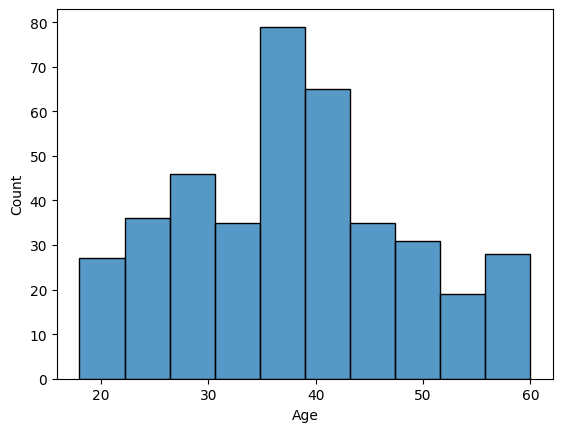

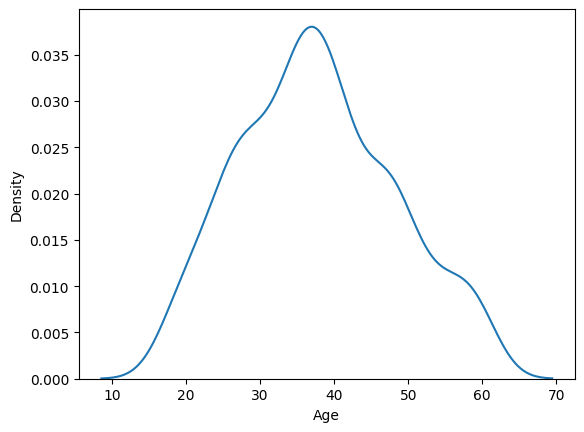

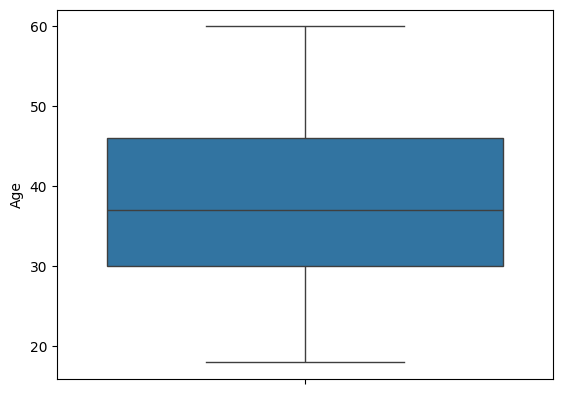

In [50]:
cont_analysis(data,'Age')

min       1.500000e+04
max       5.000000e+06
mean      8.236658e+04
median    7.000000e+04
var       6.183755e+10
std       2.486716e+05
skew      1.943000e+01
kurt      3.851100e+02
Name: EstimatedSalary, dtype: float64


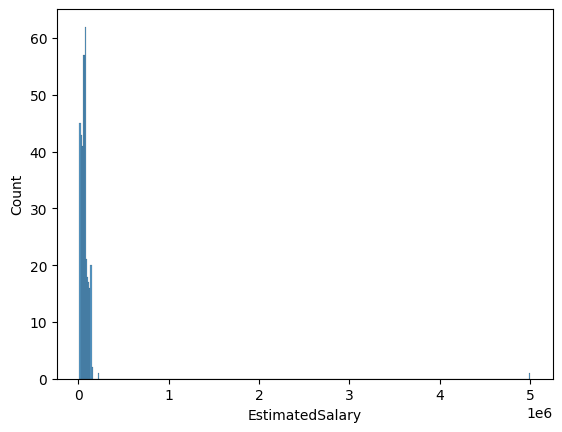

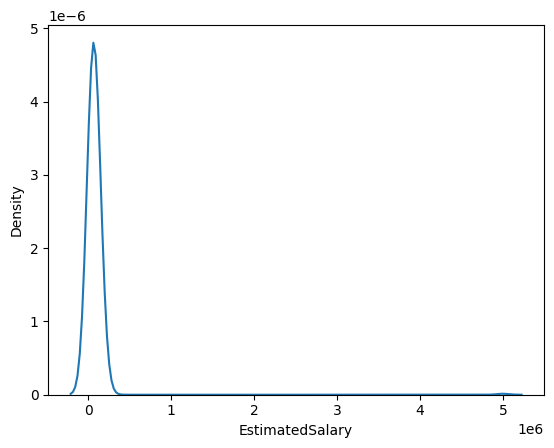

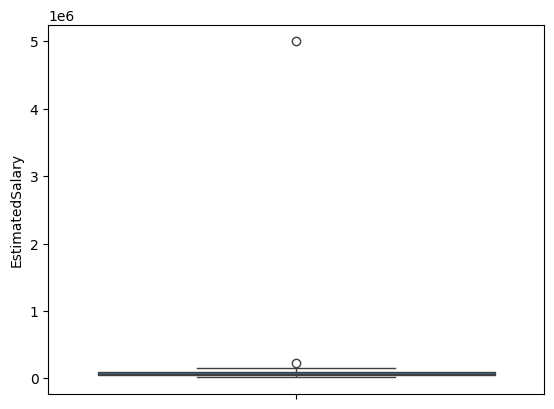

In [51]:
cont_analysis(data,'EstimatedSalary')

In [52]:
## Estimated Salary has few extreme outliers

In [53]:
## Handle outliers using IQR

def get_iqr_limits(data,col):
  q1 = data[col].quantile(0.25)
  q3 = data[col].quantile(0.75)

  iqr = q3-q1
  ul = q3+1.5*iqr
  ll = q1-1.5*iqr

  return ll,ul

ll,ul = get_iqr_limits(data,'EstimatedSalary')

print(ll,ul)

-24500.0 155500.0


In [54]:
outliers = data[data.EstimatedSalary > ul]
outliers

## remove these outliers

,User ID,Date,Country,Gender,Age,EstimatedSalary,Purchased
161,15734234,8/22/2012,France,Male,36,5000000.0,1
281,15613334,2/15/2013,Italy,Female,54,233000.0,1


In [55]:
print("data.shape with outliers = ",data.shape)
data.drop(outliers.index,axis=0,inplace=True)
print("data.shape without outliers = ",data.shape)

data.shape with outliers =  (401, 7)
data.shape without outliers =  (399, 7)


min       1.500000e+04
max       1.500000e+05
mean      6.966416e+04
median    7.000000e+04
var       1.167917e+09
std       3.417480e+04
skew      5.000000e-01
kurt     -4.200000e-01
Name: EstimatedSalary, dtype: float64


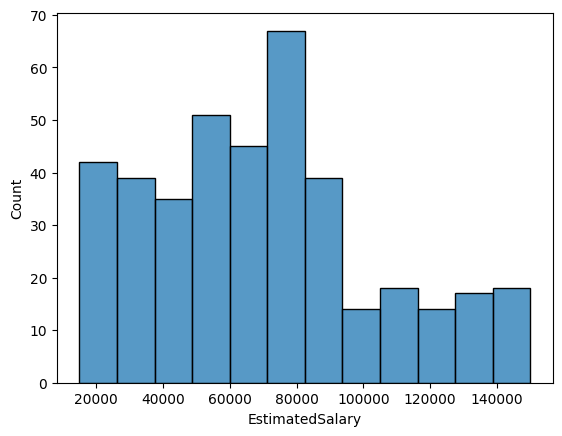

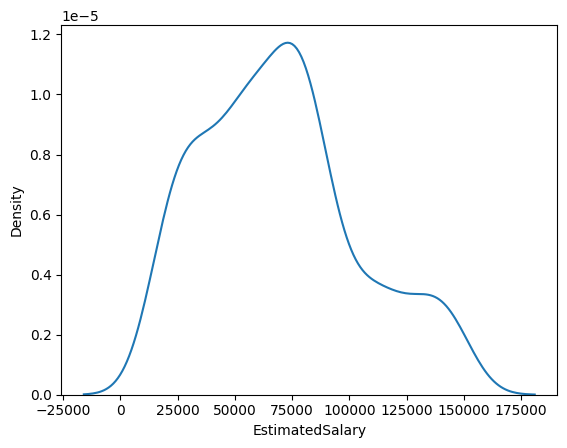

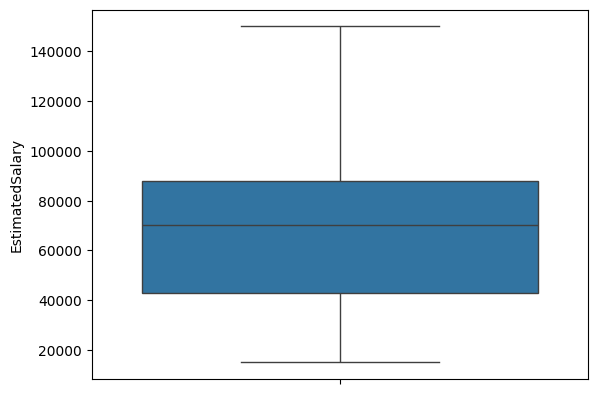

In [56]:
cont_analysis(data,'EstimatedSalary')

# Observation -> skewness due to outiliers is removed

min       1.500000e+04
max       5.000000e+06
mean      8.236658e+04
median    7.000000e+04
var       6.183755e+10
std       2.486716e+05
skew      1.943000e+01
kurt      3.851100e+02
Name: EstimatedSalary, dtype: float64


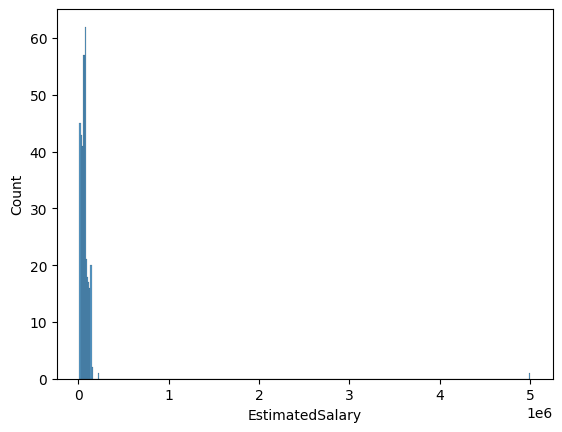

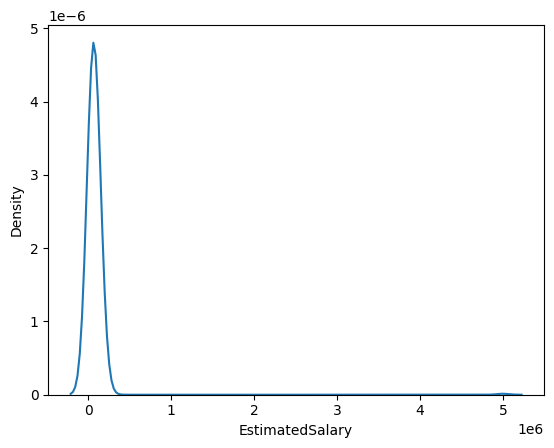

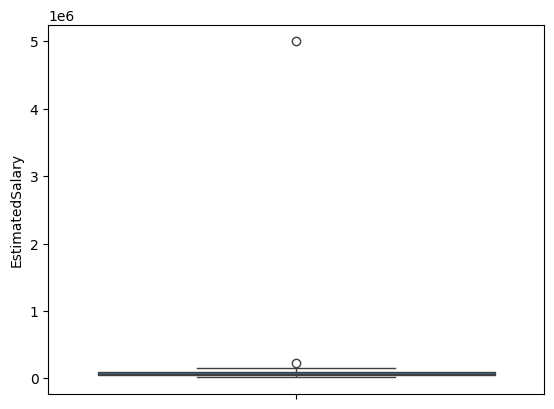

In [57]:
## If we were not allowed to drop the outliers, we could have also done log transformation

data2 = dataset.copy()

data2.dropna(inplace=True)
cont_analysis(data2,'EstimatedSalary')

min        9.62
max       15.42
mean      11.03
median    11.16
var        0.36
std        0.60
skew       0.50
kurt       6.30
Name: log_salary, dtype: float64


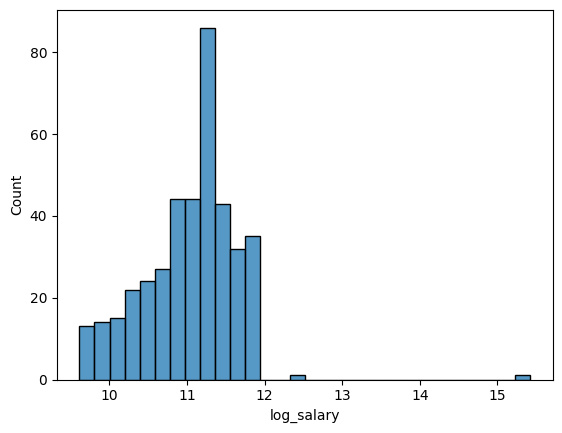

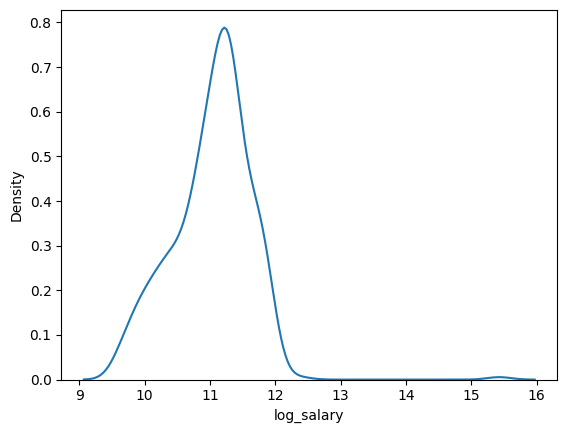

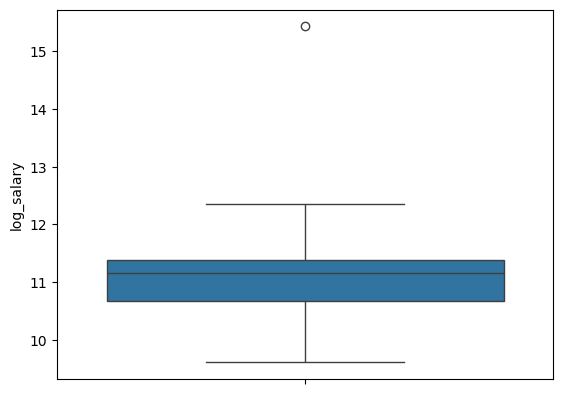

In [58]:
data2['log_salary'] = np.log(data2['EstimatedSalary'])
cont_analysis(data2,'log_salary')

In [59]:
def cat_disc_analysis(data,col):
  print("Value Counts for",col)
  val_cnt = data[col].value_counts()
  print(val_cnt)
  print("Count of null values = ",data[col].isna().sum())

  sns.countplot(x=col,data=data)
  plt.show()

  plt.pie(val_cnt,labels=val_cnt.index,autopct='%1.1f%%')
  plt.show()



In [60]:
data

,User ID,Date,Country,Gender,Age,EstimatedSalary,Purchased
0,15624510,01-03-2012,France,Male,19,19000.0,0
1,15810944,01-04-2012,Italy,Male,35,20000.0,0
2,15668575,01-05-2012,France,Female,26,43000.0,0
3,15603246,01-06-2012,Germany,Female,27,57000.0,0
4,15804002,01-09-2012,France,Male,19,76000.0,0
...,...,...,...,...,...,...,...
398,15691863,08-05-2013,France,Female,46,41000.0,1
399,15706071,08-06-2013,Italy,Male,51,23000.0,1
400,15654296,08-07-2013,Italy,Female,50,20000.0,1
401,15755018,08-08-2013,Germany,Male,36,33000.0,0


Value Counts for Gender
Gender
Female    202
Male      197
Name: count, dtype: int64
Count of null values =  0


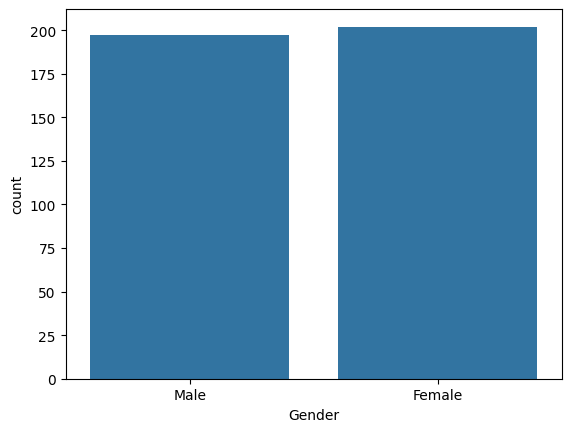

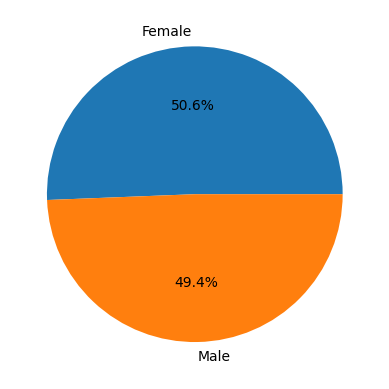

In [61]:
cat_disc_analysis(data,'Gender')

Value Counts for Country
Country
Italy        139
Germany      132
France       124
]Italy&        2
]Germany&      1
Germany&       1
Name: count, dtype: int64
Count of null values =  0


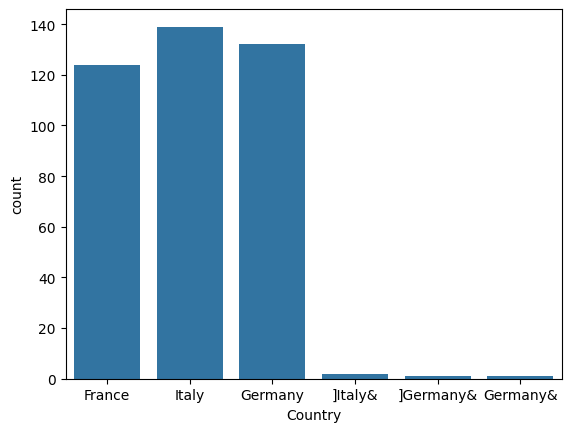

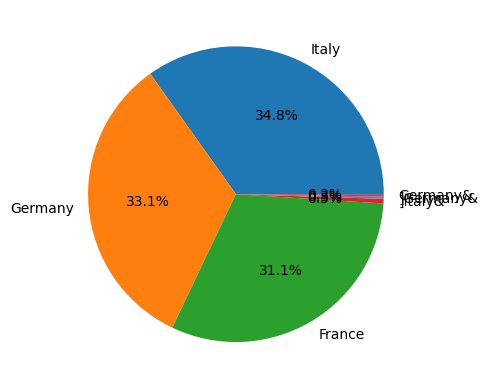

In [62]:
cat_disc_analysis(data,'Country')

In [63]:
# Country column has some wrong values, we need to clean them
import re
data['Country'] = data['Country'].apply(lambda x : re.sub(r"[^A-Za-z]",'',x))

Value Counts for Country
Country
Italy      141
Germany    134
France     124
Name: count, dtype: int64
Count of null values =  0


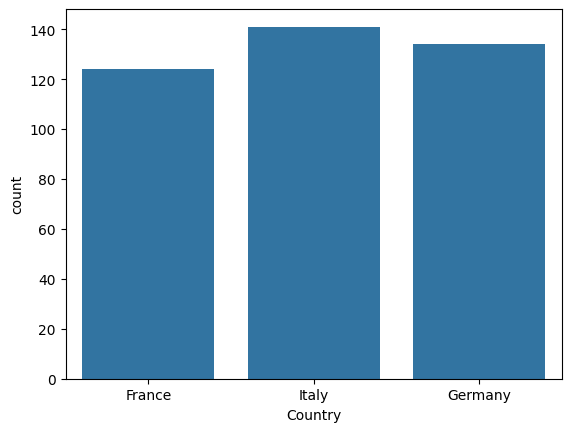

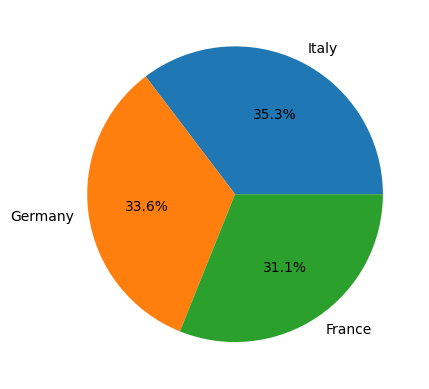

In [64]:
cat_disc_analysis(data,'Country')

In [73]:
## Feature Encoding

## as categorical columns are nominal -> we'll go with OneHotEncoding

from sklearn.preprocessing import OneHotEncoder


ohe = OneHotEncoder(sparse_output=False) ## sparse_output=False is needed to get a numpy array output

encoded = ohe.fit_transform(data[['Gender','Country']])

encoded

data[ohe.get_feature_names_out()] = encoded

data

,User ID,Date,Country,Gender,Age,EstimatedSalary,Purchased,Gender_Female,Gender_Male,Country_France,Country_Germany,Country_Italy
0,15624510,01-03-2012,France,Male,19,19000.0,0,0.0,1.0,1.0,0.0,0.0
1,15810944,01-04-2012,Italy,Male,35,20000.0,0,0.0,1.0,0.0,0.0,1.0
2,15668575,01-05-2012,France,Female,26,43000.0,0,1.0,0.0,1.0,0.0,0.0
3,15603246,01-06-2012,Germany,Female,27,57000.0,0,1.0,0.0,0.0,1.0,0.0
4,15804002,01-09-2012,France,Male,19,76000.0,0,0.0,1.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
398,15691863,08-05-2013,France,Female,46,41000.0,1,1.0,0.0,1.0,0.0,0.0
399,15706071,08-06-2013,Italy,Male,51,23000.0,1,0.0,1.0,0.0,0.0,1.0
400,15654296,08-07-2013,Italy,Female,50,20000.0,1,1.0,0.0,0.0,0.0,1.0
401,15755018,08-08-2013,Germany,Male,36,33000.0,0,0.0,1.0,0.0,1.0,0.0


In [74]:
data['Date']

,Date
0,01-03-2012
1,01-04-2012
2,01-05-2012
3,01-06-2012
4,01-09-2012
...,...
398,08-05-2013
399,08-06-2013
400,08-07-2013
401,08-08-2013


In [78]:
## Convert string datatype of date into Datetime
data['Datetime'] = pd.to_datetime(data['Date'],format='mixed',dayfirst=True,infer_datetime_format=True) # YYYY-MM-DD

data

/tmp/ipykernel_4594/339158316.py:2: UserWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  data['Datetime'] = pd.to_datetime(data['Date'],format='mixed',dayfirst=True,infer_datetime_format=True) # YYYY-MM-DD


,User ID,Date,Country,Gender,Age,EstimatedSalary,Purchased,Gender_Female,Gender_Male,Country_France,Country_Germany,Country_Italy,Datetime
0,15624510,2012-03-01,France,Male,19,19000.0,0,0.0,1.0,1.0,0.0,0.0,2012-03-01
1,15810944,2012-04-01,Italy,Male,35,20000.0,0,0.0,1.0,0.0,0.0,1.0,2012-04-01
2,15668575,2012-05-01,France,Female,26,43000.0,0,1.0,0.0,1.0,0.0,0.0,2012-05-01
3,15603246,2012-06-01,Germany,Female,27,57000.0,0,1.0,0.0,0.0,1.0,0.0,2012-06-01
4,15804002,2012-09-01,France,Male,19,76000.0,0,0.0,1.0,1.0,0.0,0.0,2012-09-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...
398,15691863,2013-05-08,France,Female,46,41000.0,1,1.0,0.0,1.0,0.0,0.0,2013-05-08
399,15706071,2013-06-08,Italy,Male,51,23000.0,1,0.0,1.0,0.0,0.0,1.0,2013-06-08
400,15654296,2013-07-08,Italy,Female,50,20000.0,1,1.0,0.0,0.0,0.0,1.0,2013-07-08
401,15755018,2013-08-08,Germany,Male,36,33000.0,0,0.0,1.0,0.0,1.0,0.0,2013-08-08


In [79]:
data['Datetime']

,Datetime
0,2012-03-01
1,2012-04-01
2,2012-05-01
3,2012-06-01
4,2012-09-01
...,...
398,2013-05-08
399,2013-06-08
400,2013-07-08
401,2013-08-08


In [80]:
## convert the Date column into components like -> Date, Month, year, week, day of week

data['Date'] = data['Datetime'].dt.day

data['Month'] = data['Datetime'].dt.month

data['Year'] = data['Datetime'].dt.year

data['Day'] = data['Datetime'].dt.dayofweek


data

,User ID,Date,Country,Gender,Age,EstimatedSalary,Purchased,Gender_Female,Gender_Male,Country_France,Country_Germany,Country_Italy,Datetime,Month,Year,Day
0,15624510,1,France,Male,19,19000.0,0,0.0,1.0,1.0,0.0,0.0,2012-03-01,3,2012,3
1,15810944,1,Italy,Male,35,20000.0,0,0.0,1.0,0.0,0.0,1.0,2012-04-01,4,2012,6
2,15668575,1,France,Female,26,43000.0,0,1.0,0.0,1.0,0.0,0.0,2012-05-01,5,2012,1
3,15603246,1,Germany,Female,27,57000.0,0,1.0,0.0,0.0,1.0,0.0,2012-06-01,6,2012,4
4,15804002,1,France,Male,19,76000.0,0,0.0,1.0,1.0,0.0,0.0,2012-09-01,9,2012,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
398,15691863,8,France,Female,46,41000.0,1,1.0,0.0,1.0,0.0,0.0,2013-05-08,5,2013,2
399,15706071,8,Italy,Male,51,23000.0,1,0.0,1.0,0.0,0.0,1.0,2013-06-08,6,2013,5
400,15654296,8,Italy,Female,50,20000.0,1,1.0,0.0,0.0,0.0,1.0,2013-07-08,7,2013,0
401,15755018,8,Germany,Male,36,33000.0,0,0.0,1.0,0.0,1.0,0.0,2013-08-08,8,2013,3


In [84]:
## When temporal features are present -> handle them properly

## In this use case -> date, day, month , year are very important from ads perspective

In [86]:
data.columns

Index(['User ID', 'Date', 'Country', 'Gender', 'Age', 'EstimatedSalary',
       'Purchased', 'Gender_Female', 'Gender_Male', 'Country_France',
       'Country_Germany', 'Country_Italy', 'Datetime', 'Month', 'Year', 'Day'],
      dtype='object')

In [87]:
## Feature Selection

features = [ 'Age', 'EstimatedSalary','Gender_Female', 'Gender_Male', 'Country_France',
       'Country_Germany', 'Country_Italy','Date','Month', 'Year', 'Day']

target = ['Purchased']

clean_data = data[features+target]

clean_data

,Age,EstimatedSalary,Gender_Female,Gender_Male,Country_France,Country_Germany,Country_Italy,Date,Month,Year,Day,Purchased
0,19,19000.0,0.0,1.0,1.0,0.0,0.0,1,3,2012,3,0
1,35,20000.0,0.0,1.0,0.0,0.0,1.0,1,4,2012,6,0
2,26,43000.0,1.0,0.0,1.0,0.0,0.0,1,5,2012,1,0
3,27,57000.0,1.0,0.0,0.0,1.0,0.0,1,6,2012,4,0
4,19,76000.0,0.0,1.0,1.0,0.0,0.0,1,9,2012,5,0
...,...,...,...,...,...,...,...,...,...,...,...,...
398,46,41000.0,1.0,0.0,1.0,0.0,0.0,8,5,2013,2,1
399,51,23000.0,0.0,1.0,0.0,0.0,1.0,8,6,2013,5,1
400,50,20000.0,1.0,0.0,0.0,0.0,1.0,8,7,2013,0,1
401,36,33000.0,0.0,1.0,0.0,1.0,0.0,8,8,2013,3,0


In [114]:
## train - test split

from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(clean_data[features],clean_data['Purchased'],test_size=0.2)
print("Train data = ",x_train.shape)
print("Test data = ",x_test.shape)

Train data =  (319, 11)
Test data =  (80, 11)


In [115]:
## Feature Scaling

from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

x_train = sc.fit_transform(x_train)

In [116]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(x_train,y_train)

LogisticRegression()

In [117]:
y_pred = model.predict(x_train)
y_pred

## internally model produces propbabilities
# if prob >=0.5 -> y_pred = 1 else y_pred = 0

array([1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1,
       0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1,
       0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1,
       1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0,
       0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0,
       1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0,

In [118]:
from sklearn.metrics import classification_report
print(classification_report(y_train,y_pred))

              precision    recall  f1-score   support

           0       0.87      0.93      0.90       201
           1       0.87      0.76      0.81       118

    accuracy                           0.87       319
   macro avg       0.87      0.85      0.85       319
weighted avg       0.87      0.87      0.87       319



In [119]:
x_test = sc.transform(x_test)
y_pred = model.predict(x_test)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.83      0.87      0.85        55
           1       0.68      0.60      0.64        25

    accuracy                           0.79        80
   macro avg       0.75      0.74      0.74        80
weighted avg       0.78      0.79      0.78        80



In [120]:
## Current model is giving ~85% accuracy
## We can train other models on same data to see if we get better performance

In [121]:
probs = model.predict_proba(x_test)
prob_1 = probs[:,1]
prob_1


array([6.83730103e-03, 6.27955806e-01, 9.90358987e-01, 9.30938380e-03,
       4.24117369e-01, 2.46831449e-01, 8.23076925e-04, 9.03056017e-01,
       2.09745835e-01, 1.65718648e-01, 2.65467934e-02, 4.12303102e-01,
       1.07374983e-01, 1.49187080e-01, 6.23478377e-01, 6.41640832e-03,
       7.59068148e-01, 7.08837518e-02, 2.84859732e-01, 1.43991830e-01,
       7.24085206e-01, 6.13755959e-02, 4.23658487e-01, 2.59767047e-01,
       5.84353948e-01, 9.80831538e-02, 1.25903631e-01, 4.05987729e-01,
       2.00260764e-01, 1.41487388e-01, 3.45635050e-02, 1.81232335e-01,
       1.19462941e-02, 3.29217921e-02, 3.14918535e-01, 1.72720849e-01,
       1.36204112e-01, 2.10944257e-01, 4.94873834e-03, 4.07064602e-01,
       9.43792552e-01, 2.71403447e-02, 7.65725420e-01, 9.36213343e-03,
       1.16690278e-02, 7.96518447e-02, 4.49312449e-01, 4.48817926e-01,
       2.03812016e-02, 8.98051641e-01, 8.76926089e-01, 2.24458175e-02,
       9.90154213e-02, 9.70915992e-01, 9.78751829e-01, 8.66024705e-01,
      

In [122]:
threshold = 0.7
custom_pred = (prob_1>=threshold).astype(int)
custom_pred

array([0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0])

In [123]:
print(classification_report(y_test,custom_pred))

              precision    recall  f1-score   support

           0       0.81      0.93      0.86        55
           1       0.76      0.52      0.62        25

    accuracy                           0.80        80
   macro avg       0.79      0.72      0.74        80
weighted avg       0.80      0.80      0.79        80



In [126]:
## we can see fluctuation in model performance with different splits of train and test

## Such cases occur due to small datasize, we can't tell which one is the correct model accuracy
## Solution for this : Cross Validation